
<p align="center"> In the Name of God </p>

<table style="width: 100%; text-align: center;">
  <tr>
    <td style="width: 20%;"><img src="https://i.ibb.co/yXKQmtZ/logo1.png" alt="Left Logo" width="100"></td>
    <td style="width: 60%;">
      <p>Faculty of Electrical and Computer Engineering</p>
      <p>Interactive learning - Fall 2023-2024</p>
      <p>Assignment Series 2</p>
      <p>Markov Decision Processes and Dynamic programming</p>
    </td>
    <td style="width: 20%;"><img src="https://i.ibb.co/wLjqFkw/logo2.png" alt="Right Logo" width="100"></td>
  </tr>
  
</table>
<p align="center">Fatemeh Mohammadi - 810199489</p>
<hr>



In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve
from sympy import symbols, solveset, Interval, nsolve


# <font color = lightGreen> Problem 3: 
 </font>

# <font color = lightGreen> Problem 4: 
 </font>

## PART 1: (Questions)

### 4.1.D

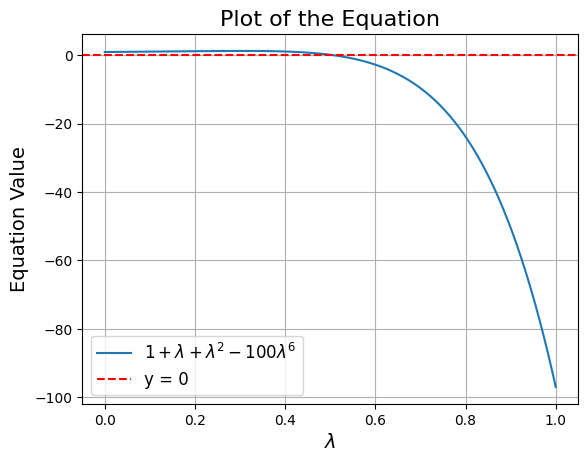

In [2]:
def equation(lambda_):
    return 1 + lambda_ + lambda_**2 - (100 * lambda_**6)

lambda_values = np.linspace(0, 1, 500)
equation_values = equation(lambda_values)

plt.plot(lambda_values, equation_values, label=r"$1 + \lambda + \lambda^2 - 100\lambda^6$")
plt.axhline(0, color='red', linestyle='--', label="y = 0")
plt.xlabel(r"$\lambda$", fontsize=14)
plt.ylabel("Equation Value", fontsize=14)
plt.title("Plot of the Equation", fontsize=16)
plt.legend(fontsize=12)
plt.grid(True)
plt.show()


In [ ]:
lambda_sym = symbols('lambda', positive=True, real=True)
equation_1 = 1 + lambda_sym + lambda_sym**2 - 100 * lambda_sym**6

root1 = nsolve(equation_1, lambda_sym, 0.9)
root1

0.510558830219454

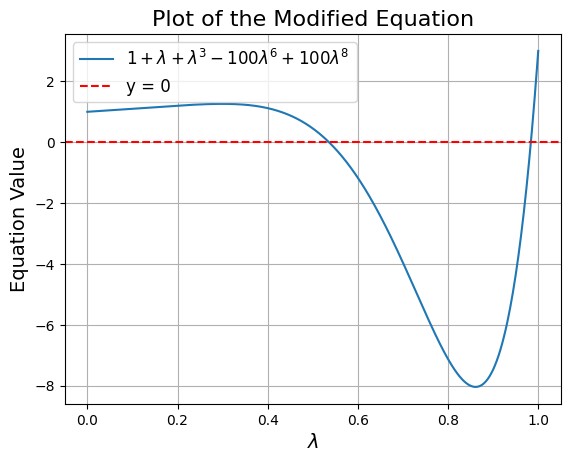

In [6]:
def modified_equation(lambda_):
    return 1 + lambda_ + lambda_**3 - (100 * lambda_**6) + (100 * lambda_**8)

lambda_values = np.linspace(0, 1, 500)
modified_equation_values = modified_equation(lambda_values)

plt.plot(lambda_values, modified_equation_values, label=r"$1 + \lambda + \lambda^3 - 100\lambda^6 + 100\lambda^8$")
plt.axhline(0, color='red', linestyle='--', label="y = 0")
plt.xlabel(r"$\lambda$", fontsize=14)
plt.ylabel("Equation Value", fontsize=14)
plt.title("Plot of the Modified Equation", fontsize=16)
plt.legend(fontsize=12)
plt.grid(True)
plt.show()


In [ ]:
lambda_sym = symbols('lambda', positive=True, real=True)
equation_2 = 1 + lambda_sym + lambda_sym**3 - 100 * lambda_sym**6 + 100 * lambda_sym**8

roots = solveset(equation_2, lambda_sym, domain=Interval(0, 1))

root1 = nsolve(equation_2, lambda_sym, 0.5)
root2 = nsolve(equation_2, lambda_sym, 0.9)
(root1, root2)

(0.535996345399022, 0.983664801927083)

## PART 2: (Simulation)

### Define MDP parameters:

In [ ]:
## State Space S:
states = list(range(11))

## Action Space A:
actions = ["Buy", "Sell"]

## Transition Probabilities P:
def transitions(current_s, a): #P(current_s,a) -> {next_s: probability = 1}
    next_s = 0
    probability = 1 # Deterministic
    if current_s == 10:  # Terminal state
        next_s = current_s
        return {next_s: probability}

    if a == "Buy":
        if current_s < 10:
            next_s = current_s + 1
        else:
            next_s = current_s
    elif a == "Sell":
        if current_s > 0:
            next_s = current_s - 1
        else:
            next_s = current_s

    return {next_s: probability}


## Reward Function R:
def rewards(current_s, a, next_s):
    reward = 0
    if current_s == 10:  # Terminal state
        return reward

    if a == "Buy":
        if next_s == 10 and current_s == 9:
            reward = 100
        else:
            reward = 0
    elif a == "Sell":
        if current_s > 0 and next_s == current_s - 1:
            reward = 1
        else:
            reward = 0
    return reward


### 4.2.A.

In [172]:
Hs = [3]

#### Policy Iteration:

In [ ]:
def finite_horizon_policy_iteration_no_sum(states, actions, H):
    policy = { (s, t): (np.random.choice(actions) if s != 10 else "No Action") for s in states for t in range(H + 1) }
    print(policy)
    while True:
        # Policy Evaluation
        V = { (s, t): 0 for s in states for t in range(H+1) }

        for t in range(H - 1, 0, -1):
            print(t)
            for s in states:
                if s == 10:  # Skip terminal state
                    continue
                a = policy[(s, t)]
                value = 0
                for next_s, prob in transitions(s, a).items():
                    value += prob * (rewards(s, a, next_s) + V[(next_s, t+1)])
                    if s==3:print(t, s, next_s, value)
                V[(s, t)] = value

        # Policy Improvement
        print("000000000000000000")
        stable = True
        for t in range(H):
            for s in states:
                if s == 10:  # Skip terminal state
                    continue

                # Find the best action
                best_action = None
                best_value = float('-inf')
                for a in actions:
                    value = 0
                    for next_s, prob in transitions(s, a).items():
                        value += prob * (rewards(s, a, next_s) + V[(next_s, t+1)])
                    if value > best_value:
                        best_value = value
                        best_action = a

                if s== 3: print(t, s, next_s, value, best_action)

                if policy[(s, t)] != best_action:
                    stable = False
                    policy[(s, t)] = best_action

        if stable:
            break  # Policy has converged
        print("1111111111111111111")

    return policy

# Solve for each horizon
policies_no_sum = {}
for H in Hs:
    optimal_policy = finite_horizon_policy_iteration_no_suimport numpy as np

def finite_horizon_value_iteration(states, actions, reward, transition, H):
    """
    Finite Horizon Value Iteration Algorithm.

    Args:
        states: List of states.
        actions: List of actions.
        reward: Reward function, r(s, a, s').
        transition: Transition function, p(s' | s, a).
        H: Horizon (finite time steps).

    Returns:
        policy: Optimal policy for each state and time step.
        value: Optimal value for each state and time step.
    """
    num_states = len(states)
    num_actions = len(actions)
    value = np.zeros((H + 1, num_states))  # Value function: V_h(s)
    policy = np.zeros((H, num_states), dtype=int)  # Policy: π_h(s)

    # Backward induction for finite horizon
    for h in range(H - 1, -1, -1):
        for s in range(num_states):
            action_values = []
            for a, action in enumerate(actions):
                total = 0
                for s_prime in range(num_states):
                    prob = transition[s, a, s_prime]
                    total += prob * (reward[s, a, s_prime] + value[h + 1, s_prime])
                action_values.append(total)
            policy[h, s] = np.argmax(action_values)
            value[h, s] = max(action_values)

    return policy, value


# Define the MDP components
states = np.arange(11)  # States: [0, 1, ..., 10]
actions = ["buy", "sell"]

# Reward function: r(s, a, s')
reward = np.zeros((11, 2, 11))
for s in range(11):
    if s > 0:
        reward[s, 1, s - 1] = 1  # Sell reward
    if s == 9:
        reward[s, 0, s + 1] = 100  # Buy reward to fill inventory

# Transition function: p(s' | s, a)
transition = np.zeros((11, 2, 11))
for s in range(11):
    if s > 0:
        transition[s, 1, s - 1] = 1  # Sell transition
    if s < 10:
        transition[s, 0, s + 1] = 1  # Buy transition

# Run for different horizons
H_values = [4, 7, 10]  # Example horizons
results = {}
for H in H_values:
    policy, value = finite_horizon_value_iteration(states, actions, reward, transition, H)
    results[H] = (policy, value)

# Display results for H=4, H=7, and H=10
for H in H_values:
    print(f"\nHorizon: {H}")
    print("Optimal Policy:")
    print(results[H][0])
    print("Value Function:")
    print(results[H][1])
m(states, actions, 7)
    policies_no_sum[H] = optimal_policy



{(0, 0): 'Sell', (0, 1): 'Buy', (0, 2): 'Buy', (0, 3): 'Buy', (0, 4): 'Sell', (0, 5): 'Buy', (0, 6): 'Buy', (0, 7): 'Sell', (1, 0): 'Buy', (1, 1): 'Sell', (1, 2): 'Sell', (1, 3): 'Buy', (1, 4): 'Sell', (1, 5): 'Sell', (1, 6): 'Buy', (1, 7): 'Sell', (2, 0): 'Buy', (2, 1): 'Buy', (2, 2): 'Sell', (2, 3): 'Sell', (2, 4): 'Buy', (2, 5): 'Buy', (2, 6): 'Buy', (2, 7): 'Sell', (3, 0): 'Sell', (3, 1): 'Sell', (3, 2): 'Sell', (3, 3): 'Buy', (3, 4): 'Sell', (3, 5): 'Buy', (3, 6): 'Sell', (3, 7): 'Buy', (4, 0): 'Buy', (4, 1): 'Sell', (4, 2): 'Sell', (4, 3): 'Sell', (4, 4): 'Buy', (4, 5): 'Sell', (4, 6): 'Buy', (4, 7): 'Buy', (5, 0): 'Buy', (5, 1): 'Buy', (5, 2): 'Buy', (5, 3): 'Buy', (5, 4): 'Buy', (5, 5): 'Sell', (5, 6): 'Sell', (5, 7): 'Buy', (6, 0): 'Buy', (6, 1): 'Buy', (6, 2): 'Buy', (6, 3): 'Buy', (6, 4): 'Buy', (6, 5): 'Buy', (6, 6): 'Sell', (6, 7): 'Sell', (7, 0): 'Buy', (7, 1): 'Sell', (7, 2): 'Buy', (7, 3): 'Sell', (7, 4): 'Buy', (7, 5): 'Buy', (7, 6): 'Buy', (7, 7): 'Buy', (8, 0): 'Buy'

#### Value Iteration: